# PHA Classification: Model and Imbalance Comparison

Predict whether an asteroid is a Potentially Hazardous Asteroid (`pha`) using the cleaned dataset. The PHA-positive class is a very small minority, so this notebook compares Logistic Regression, Random Forest, and XGBoost both **without** and **with** class-imbalance weighting. It keeps the test set untouched, reports minority-class metrics, and saves the best trained model with its preprocessing pipeline as a reusable `.pkl` artifact (no CSV files are written).

## 1. Import libraries and find the cleaned dataset

In [1]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "Data" / "pha_dataset_cleaned.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "Data" / "pha_dataset_cleaned.csv"
TARGET = "pha"
RANDOM_STATE = 42
print("Using cleaned dataset:", DATA_PATH)

Using cleaned dataset: d:\Guvi\PDA\Data\pha_dataset_cleaned.csv


## 2. Load data and inspect class balance

In [24]:
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Dataset size: {df.shape[0]:,} rows x {df.shape[1]} columns")
target_counts = df[TARGET].value_counts(dropna=False)
target_percent = df[TARGET].value_counts(normalize=True, dropna=False).mul(100)
class_balance = pd.DataFrame({"count": target_counts, "percent": target_percent})
display(class_balance)
display(df.head())

Dataset size: 958,524 rows x 45 columns


,count,percent
pha,,
N,956458,99.78446
Y,2066,0.21554


,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


## 3. Prepare the binary target

In [25]:
df = df.dropna(subset=[TARGET]).copy()
target_values = df[TARGET].astype(str).str.strip().str.upper()
target_encoder = LabelEncoder()
y = pd.Series(target_encoder.fit_transform(target_values), index=df.index, name=TARGET)
if len(target_encoder.classes_) != 2:
    raise ValueError(f"Expected two PHA target classes, found {target_encoder.classes_.tolist()}")

class_to_code = {str(label): int(code) for code, label in enumerate(target_encoder.classes_)}
positive_label = class_to_code.get("Y", int(y.max()))
negative_label = 1 - positive_label
print("Target encoding:", class_to_code)
print("PHA positive label:", positive_label)
print(f"Positive share: {100 * (y == positive_label).mean():.4f}%")
display(y.value_counts().sort_index().rename("count").to_frame())

Target encoding: {'N': 0, 'Y': 1}
PHA positive label: 1
Positive share: 0.2155%


,count
pha,
0,956458
1,2066


## 4. Select predictors and prevent target leakage

Drop identifiers and names. Also exclude `neo`, MOID (`moid`, `moid_ld`), absolute magnitude (`H`), and orbital `class`: these can directly reveal or closely encode the PHA designation. Keep measured physical and orbital parameters that do not directly define the target.

In [26]:
excluded_columns = {
    TARGET, "id", "spkid", "pdes", "name", "full_name", "prefix", "orbit_id",
    "neo", "moid", "moid_ld", "H", "class",
}
feature_columns = [column for column in df.columns if column not in excluded_columns]
X = df[feature_columns].copy()

numeric_columns = X.select_dtypes(include="number").columns.tolist()
categorical_columns = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
unsupported_columns = [column for column in X.columns if column not in numeric_columns + categorical_columns]
if unsupported_columns:
    raise TypeError(f"Unsupported predictor data types: {unsupported_columns}")

print(f"Predictors: {len(feature_columns)} ({len(numeric_columns)} numeric, {len(categorical_columns)} categorical)")
print("Numeric predictors:", numeric_columns)
print("Categorical predictors:", categorical_columns)

Predictors: 32 (31 numeric, 1 categorical)
Numeric predictors: ['diameter', 'albedo', 'diameter_sigma', 'epoch', 'epoch_mjd', 'epoch_cal', 'e', 'a', 'q', 'i', 'om', 'w', 'ma', 'ad', 'n', 'tp', 'tp_cal', 'per', 'per_y', 'sigma_e', 'sigma_a', 'sigma_q', 'sigma_i', 'sigma_om', 'sigma_w', 'sigma_ma', 'sigma_ad', 'sigma_n', 'sigma_tp', 'sigma_per', 'rms']
Categorical predictors: ['equinox']


## 5. Stratified train-test split

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
print("Training counts:")
display(y_train.value_counts().sort_index().rename("count").to_frame())
print("Test counts:")
display(y_test.value_counts().sort_index().rename("count").to_frame())

Training rows: 766,819; test rows: 191,705
Training counts:


,count
pha,
0,765166
1,1653


Test counts:


,count
pha,
0,191292
1,413


## 6. Impute, encode, and scale predictors

Fit the preprocessing on training features only. Numeric columns use median imputation and scaling; categorical columns use most-frequent imputation and one-hot encoding. The one-hot output remains sparse to avoid using excessive memory.

In [28]:
numeric_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(with_mean=False),
)
categorical_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=True),
)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ],
    remainder="drop",
    sparse_threshold=1.0,
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("Processed train shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed train shape: (766819, 32)
Processed test shape: (191705, 32)


## 7. Configure models with and without imbalance handling

The unweighted models establish a baseline. The weighted versions use `class_weight="balanced"` (or XGBoost `scale_pos_weight`) estimated from the training split only. This changes training penalties, not the test-set class proportions.

In [29]:
negative_count = int((y_train == negative_label).sum())
positive_count = int((y_train == positive_label).sum())
if positive_count == 0 or negative_count == 0:
    raise ValueError("Both PHA classes must be present in the training split.")
scale_pos_weight = negative_count / positive_count
print(f"Training positives: {positive_count:,}; negatives: {negative_count:,}")
print(f"Positive class weighting factor: {scale_pos_weight:.2f}")

models = {
    "Logistic Regression (no weighting)": LogisticRegression(
        max_iter=1000, solver="liblinear", class_weight=None, random_state=RANDOM_STATE,
    ),
    "Logistic Regression (balanced)": LogisticRegression(
        max_iter=1000, solver="liblinear", class_weight="balanced", random_state=RANDOM_STATE,
    ),
    "Random Forest (no weighting)": RandomForestClassifier(
        n_estimators=100, max_depth=18, min_samples_leaf=2, max_samples=0.8,
        class_weight=None, n_jobs=-1, random_state=RANDOM_STATE,
    ),
    "Random Forest (balanced)": RandomForestClassifier(
        n_estimators=100, max_depth=18, min_samples_leaf=2, max_samples=0.8,
        class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE,
    ),
    "XGBoost (no weighting)": XGBClassifier(
        n_estimators=150, max_depth=5, learning_rate=0.08, subsample=0.8,
        colsample_bytree=0.8, objective="binary:logistic", eval_metric="logloss",
        tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE,
    ),
    "XGBoost (balanced)": XGBClassifier(
        n_estimators=150, max_depth=5, learning_rate=0.08, subsample=0.8,
        colsample_bytree=0.8, scale_pos_weight=scale_pos_weight,
        objective="binary:logistic", eval_metric="logloss", tree_method="hist",
        n_jobs=-1, random_state=RANDOM_STATE,
    ),
}

Training positives: 1,653; negatives: 765,166
Positive class weighting factor: 462.90


## 8. Train models and compare minority-aware metrics

Accuracy is not used as the primary score because an always-negative classifier would appear highly accurate. Average precision (area under the precision-recall curve), positive-class recall, precision, F1, balanced accuracy, and ROC-AUC are reported at the default 0.5 decision threshold.

In [30]:
results = []
predictions = {}
positive_probabilities = {}

for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train_processed, y_train)
    y_pred = model.predict(X_test_processed)
    positive_column = int(np.flatnonzero(model.classes_ == positive_label)[0])
    y_probability = model.predict_proba(X_test_processed)[:, positive_column]
    predictions[model_name] = y_pred
    positive_probabilities[model_name] = y_probability

    results.append({
        "model": model_name,
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "precision_PHA": precision_score(y_test, y_pred, pos_label=positive_label, zero_division=0),
        "recall_PHA": recall_score(y_test, y_pred, pos_label=positive_label, zero_division=0),
        "F1_PHA": f1_score(y_test, y_pred, pos_label=positive_label, zero_division=0),
        "average_precision": average_precision_score(y_test == positive_label, y_probability),
        "ROC_AUC": roc_auc_score(y_test == positive_label, y_probability),
    })
    print(f"Finished {model_name}.")

results_df = pd.DataFrame(results).set_index("model").sort_values("average_precision", ascending=False)
display(results_df.style.format("{:.4f}"))

Training Logistic Regression (no weighting)...
Finished Logistic Regression (no weighting).
Training Logistic Regression (balanced)...
Finished Logistic Regression (balanced).
Training Random Forest (no weighting)...
Finished Random Forest (no weighting).
Training Random Forest (balanced)...
Finished Random Forest (balanced).
Training XGBoost (no weighting)...
Finished XGBoost (no weighting).
Training XGBoost (balanced)...
Finished XGBoost (balanced).


,balanced_accuracy,precision_PHA,recall_PHA,F1_PHA,average_precision,ROC_AUC
model,,,,,,
XGBoost (no weighting),0.6922,0.6211,0.3850,0.4753,0.5746,0.9983
XGBoost (balanced),0.9702,0.2414,0.9467,0.3847,0.4728,0.9980
Random Forest (no weighting),0.5991,0.5857,0.1985,0.2966,0.4477,0.9980
Random Forest (balanced),0.9214,0.2811,0.8475,0.4222,0.3221,0.9973
Logistic Regression (no weighting),0.5325,0.2596,0.0654,0.1044,0.2115,0.9942
Logistic Regression (balanced),0.9897,0.0949,1.0000,0.1733,0.1927,0.9949


## 9. Compare precision-recall curves

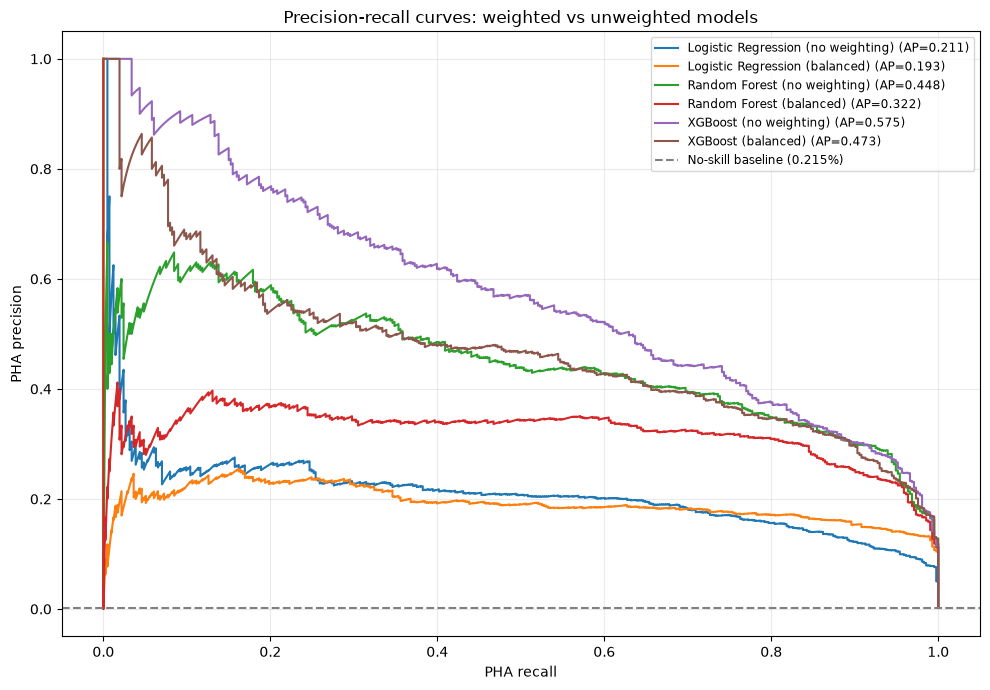

In [31]:
plt.figure(figsize=(10, 7))
for model_name, y_probability in positive_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test == positive_label, y_probability)
    ap = average_precision_score(y_test == positive_label, y_probability)
    plt.plot(recall, precision, label=f"{model_name} (AP={ap:.3f})")

positive_rate = float((y_test == positive_label).mean())
plt.axhline(positive_rate, color="gray", linestyle="--", label=f"No-skill baseline ({positive_rate:.3%})")
plt.xlabel("PHA recall")
plt.ylabel("PHA precision")
plt.title("Precision-recall curves: weighted vs unweighted models")
plt.legend(loc="best", fontsize="small")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 10. Inspect confusion matrices and positive-class reports

In [32]:
class_names = [str(label) for label in target_encoder.classes_]
for model_name, y_pred in predictions.items():
    print(f"\n{model_name} — classification report")
    print(classification_report(y_test, y_pred, labels=[negative_label, positive_label], target_names=["Not PHA", "PHA"], zero_division=0))
    print("Confusion matrix (true rows, predicted columns; order: Not PHA, PHA):")
    display(pd.DataFrame(
        confusion_matrix(y_test, y_pred, labels=[negative_label, positive_label]),
        index=["actual_Not_PHA", "actual_PHA"],
        columns=["predicted_Not_PHA", "predicted_PHA"],
    ))


Logistic Regression (no weighting) — classification report
              precision    recall  f1-score   support

     Not PHA       1.00      1.00      1.00    191292
         PHA       0.26      0.07      0.10       413

    accuracy                           1.00    191705
   macro avg       0.63      0.53      0.55    191705
weighted avg       1.00      1.00      1.00    191705

Confusion matrix (true rows, predicted columns; order: Not PHA, PHA):


,predicted_Not_PHA,predicted_PHA
actual_Not_PHA,191215,77
actual_PHA,386,27



Logistic Regression (balanced) — classification report
              precision    recall  f1-score   support

     Not PHA       1.00      0.98      0.99    191292
         PHA       0.09      1.00      0.17       413

    accuracy                           0.98    191705
   macro avg       0.55      0.99      0.58    191705
weighted avg       1.00      0.98      0.99    191705

Confusion matrix (true rows, predicted columns; order: Not PHA, PHA):


,predicted_Not_PHA,predicted_PHA
actual_Not_PHA,187353,3939
actual_PHA,0,413



Random Forest (no weighting) — classification report
              precision    recall  f1-score   support

     Not PHA       1.00      1.00      1.00    191292
         PHA       0.59      0.20      0.30       413

    accuracy                           1.00    191705
   macro avg       0.79      0.60      0.65    191705
weighted avg       1.00      1.00      1.00    191705

Confusion matrix (true rows, predicted columns; order: Not PHA, PHA):


...

,predicted_Not_PHA,predicted_PHA
actual_Not_PHA,190397,895
actual_PHA,63,350



XGBoost (no weighting) — classification report
              precision    recall  f1-score   support

     Not PHA       1.00      1.00      1.00    191292
         PHA       0.62      0.38      0.48       413

    accuracy                           1.00    191705
   macro avg       0.81      0.69      0.74    191705
weighted avg       1.00      1.00      1.00    191705

Confusion matrix (true rows, predicted columns; order: Not PHA, PHA):


,predicted_Not_PHA,predicted_PHA
actual_Not_PHA,191195,97
actual_PHA,254,159



XGBoost (balanced) — classification report
              precision    recall  f1-score   support

     Not PHA       1.00      0.99      1.00    191292
         PHA       0.24      0.95      0.38       413

    accuracy                           0.99    191705
   macro avg       0.62      0.97      0.69    191705
weighted avg       1.00      0.99      1.00    191705

Confusion matrix (true rows, predicted columns; order: Not PHA, PHA):


,predicted_Not_PHA,predicted_PHA
actual_Not_PHA,190063,1229
actual_PHA,22,391


## 11. Compare the effect of class weighting

Compare each weighted model with its unweighted version. Weighting often improves minority recall while reducing precision, so choose a model based on the project's desired false-negative/false-positive trade-off.

In [35]:
weighting_comparison = pd.DataFrame({
    "Logistic Regression": {
        "unweighted_average_precision": results_df.loc["Logistic Regression (no weighting)", "average_precision"],
        "weighted_average_precision": results_df.loc["Logistic Regression (balanced)", "average_precision"],
        "unweighted_recall": results_df.loc["Logistic Regression (no weighting)", "recall_PHA"],
        "weighted_recall": results_df.loc["Logistic Regression (balanced)", "recall_PHA"],
    },
    "Random Forest": {
        "unweighted_average_precision": results_df.loc["Random Forest (no weighting)", "average_precision"],
        "weighted_average_precision": results_df.loc["Random Forest (balanced)", "average_precision"],
        "unweighted_recall": results_df.loc["Random Forest (no weighting)", "recall_PHA"],
        "weighted_recall": results_df.loc["Random Forest (balanced)", "recall_PHA"],
    },
    "XGBoost": {
        "unweighted_average_precision": results_df.loc["XGBoost (no weighting)", "average_precision"],
        "weighted_average_precision": results_df.loc["XGBoost (balanced)", "average_precision"],
        "unweighted_recall": results_df.loc["XGBoost (no weighting)", "recall_PHA"],
        "weighted_recall": results_df.loc["XGBoost (balanced)", "recall_PHA"],
    },
}).T
display(weighting_comparison.style.format("{:.4f}"))

best_model_name = results_df["average_precision"].idxmax()
best_model = models[best_model_name]
print(f"Highest test average precision: {best_model_name}")

MODEL_PATH = PROJECT_ROOT / "Models" / "pha_classifier.pkl"
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
model_artifact = {
    "model": best_model,
    "preprocessor": preprocessor,
    "target_encoder": target_encoder,
    "feature_columns": feature_columns,
    "target_column": TARGET,
    "positive_label": positive_label,
    "decision_threshold": 0.5,
    "model_name": best_model_name,
}
with MODEL_PATH.open("wb") as model_file:
    pickle.dump(model_artifact, model_file, protocol=pickle.HIGHEST_PROTOCOL)

# Reload and verify the saved artifact reproduces the selected model's test predictions.
with MODEL_PATH.open("rb") as model_file:
    loaded_artifact = pickle.load(model_file)
loaded_predictions = loaded_artifact["model"].predict(X_test_processed)
np.testing.assert_array_equal(loaded_predictions, predictions[best_model_name])
print(f"Saved and verified model: {MODEL_PATH}")
print("No new dataset or results CSV was written.")

,unweighted_average_precision,weighted_average_precision,unweighted_recall,weighted_recall
Logistic Regression,0.2115,0.1927,0.0654,1.0000
Random Forest,0.4477,0.3221,0.1985,0.8475
XGBoost,0.5746,0.4728,0.3850,0.9467


Highest test average precision: XGBoost (no weighting)
Saved and verified model: d:\Guvi\PDA\Models\pha_classifier.pkl
No new dataset or results CSV was written.


## 12. Explain the selected classifier with SHAP

TreeSHAP explains the saved best-performing XGBoost classifier. To support XGBoost's categorical metadata, this uses tree-path-dependent explanations (using the model's training-path statistics) with the raw positive-class margin (log-odds) as output; the waterfall explains the highest-scoring row in the displayed sample. Encoded category-level contributions are grouped by their original predictor when comparing against Step 5. In this sample, `q`, `e`, `per`, and `a` rank highly in both SHAP and Step 5's top-20 list; `sigma_i` is also influential in SHAP and appears in Step 5's top 20. Step 5's class-derived features ranked highly, but the classifier excludes orbit class to avoid target leakage. This is strong but not exact alignment, since the selector was a separate Random Forest workflow.

Explained model: XGBoost (no weighting); SHAP output: raw positive-class margin (log-odds)
Waterfall row index: 72; highest probability in displayed sample: 0.0248628
Rows explained: 300; transformed predictors: 32


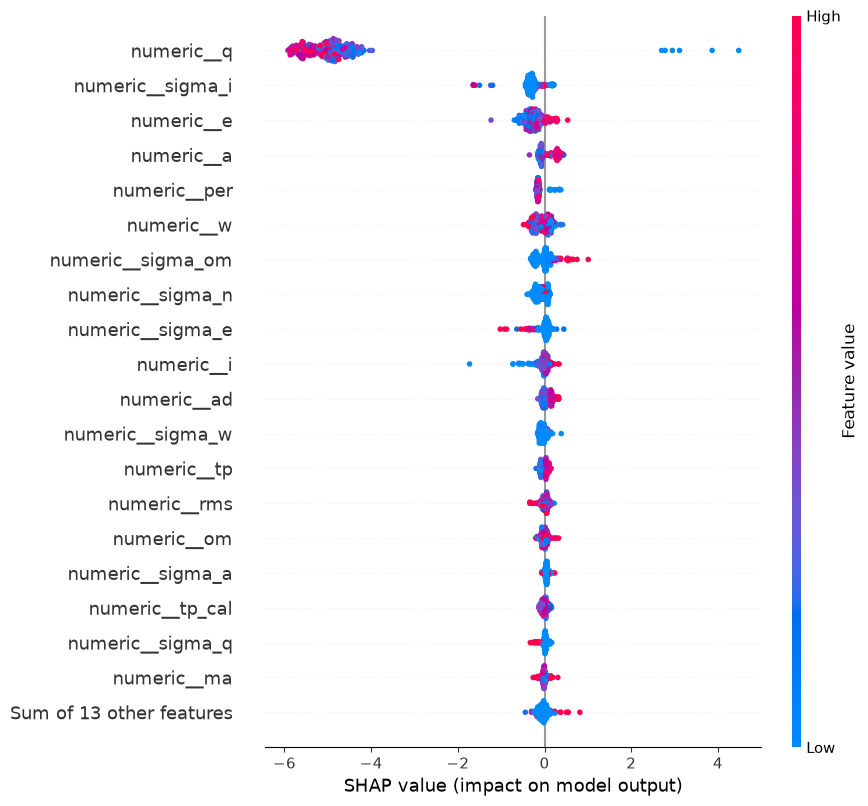

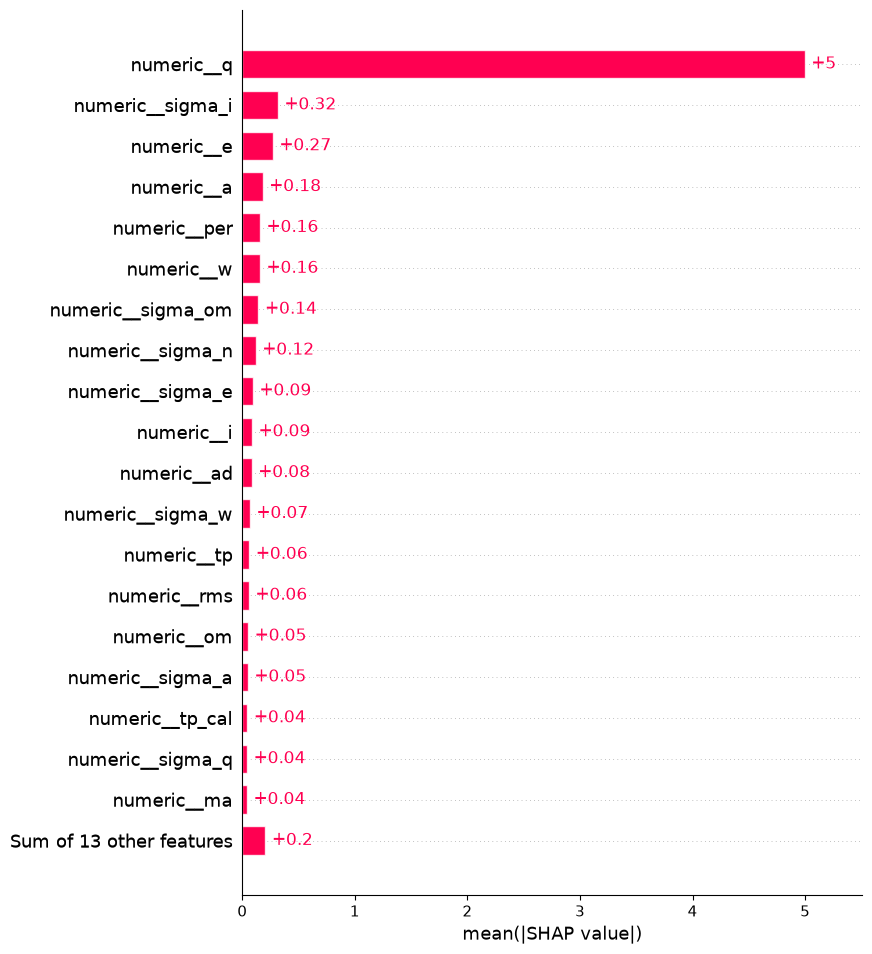

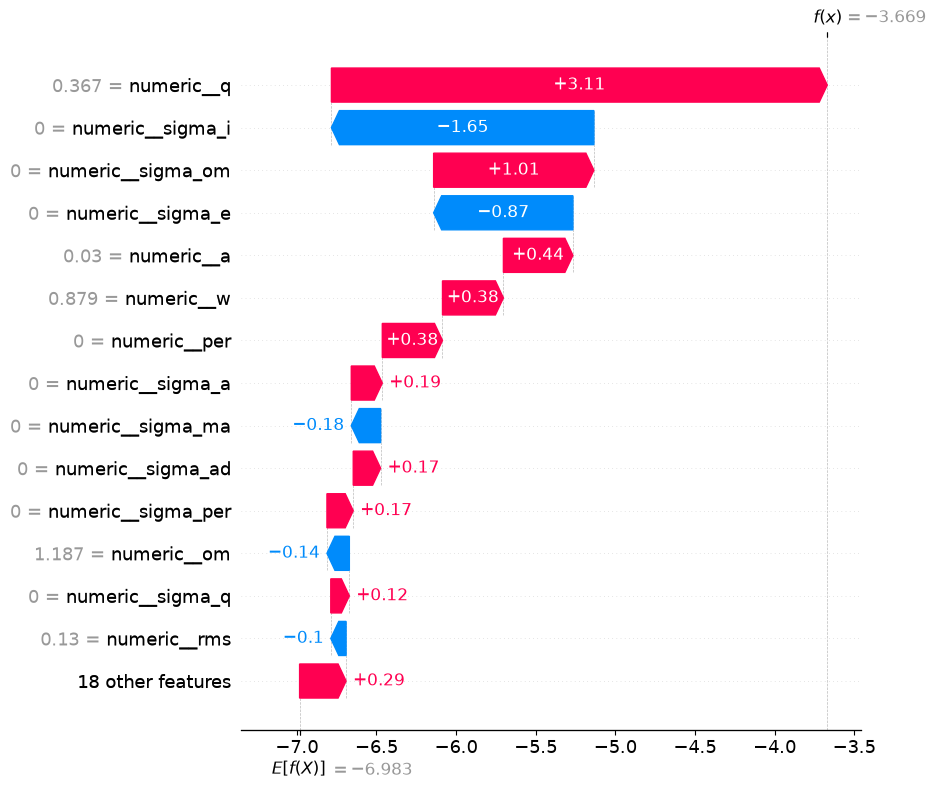

,mean_abs_shap (grouped by source predictor)
source_feature,
q,4.995650
sigma_i,0.315153
e,0.270398
a,0.180042
per,0.155996
w,0.155601
sigma_om,0.142643
sigma_n,0.118445
sigma_e,0.093407


Step 5 top-20 features: ['q', 'class_MBA', 'class_APO', 'e', 'n', 'per', 'per_y', 'ad', 'a', 'rms', 'sigma_per', 'sigma_ad', 'sigma_tp', 'sigma_a', 'sigma_i', 'sigma_e', 'sigma_q', 'i', 'sigma_n', 'om']
Shared features in both top-20 lists: ['q', 'e', 'per', 'ad', 'a', 'rms', 'sigma_tp', 'sigma_a', 'sigma_i', 'sigma_e', 'sigma_q', 'i', 'sigma_n', 'om']
Step 5 also used class-derived features and a Random Forest selector; this classifier excludes orbit class to avoid target leakage.


In [6]:
import shap
from scipy import sparse

with (PROJECT_ROOT / "Models" / "pha_classifier.pkl").open("rb") as model_file:
    shap_artifact = pickle.load(model_file)
shap_raw = pd.read_csv(DATA_PATH, usecols=shap_artifact["feature_columns"])
shap_raw = shap_raw.sample(n=min(1_200, len(shap_raw)), random_state=RANDOM_STATE).reset_index(drop=True)
shap_matrix = shap_artifact["preprocessor"].transform(shap_raw)
if sparse.issparse(shap_matrix):
    shap_matrix = shap_matrix.toarray()
shap_feature_names = shap_artifact["preprocessor"].get_feature_names_out().tolist()
explanation_size = min(300, len(shap_matrix))
shap_explain_data = shap_matrix[:explanation_size]

shap_explainer = shap.TreeExplainer(
    shap_artifact["model"],
    feature_perturbation="tree_path_dependent",
    model_output="raw",
)
shap_raw_values = shap_explainer.shap_values(shap_explain_data, check_additivity=False)
shap_positive_index = int(np.flatnonzero(shap_artifact["model"].classes_ == shap_artifact["positive_label"])[0])
if isinstance(shap_raw_values, list):
    shap_values_array = np.asarray(shap_raw_values[shap_positive_index])
else:
    shap_values_array = np.asarray(shap_raw_values)
    if shap_values_array.ndim == 3:
        shap_values_array = shap_values_array[:, :, shap_positive_index]
shap_base = np.asarray(shap_explainer.expected_value)
if shap_base.ndim > 0 and shap_base.size > 1:
    shap_base = shap_base.reshape(-1)[shap_positive_index]
else:
    shap_base = float(shap_base.reshape(-1)[0])
shap_explanation = shap.Explanation(
    values=shap_values_array,
    base_values=np.full(len(shap_explain_data), float(shap_base)),
    data=shap_explain_data,
    feature_names=shap_feature_names,
)

shap_local_index = int(np.argmax(shap_artifact["model"].predict_proba(shap_explain_data)[:, shap_positive_index]))
shap_positive_probability = shap_artifact["model"].predict_proba(shap_explain_data[shap_local_index:shap_local_index + 1])[0, shap_positive_index]
print(f"Explained model: {shap_artifact['model_name']}; SHAP output: raw positive-class margin (log-odds)")
print(f"Waterfall row index: {shap_local_index}; highest probability in displayed sample: {shap_positive_probability:.6g}")
print(f"Rows explained: {len(shap_explain_data):,}; transformed predictors: {len(shap_feature_names)}")
shap.plots.beeswarm(shap_explanation, max_display=20)
shap.plots.bar(shap_explanation, max_display=20)
shap.plots.waterfall(shap_explanation[shap_local_index], max_display=15)

def original_predictor(encoded_name):
    unprefixed = encoded_name.split("__", 1)[-1]
    for source_name in sorted(shap_artifact["feature_columns"], key=len, reverse=True):
        if unprefixed == source_name or unprefixed.startswith(source_name + "_"):
            return source_name
    return unprefixed

shap_encoded_importance = pd.DataFrame({
    "encoded_feature": shap_feature_names,
    "mean_abs_shap": np.abs(shap_values_array).mean(axis=0),
})
shap_encoded_importance["source_feature"] = shap_encoded_importance["encoded_feature"].map(original_predictor)
shap_source_importance = (
    shap_encoded_importance.groupby("source_feature")["mean_abs_shap"]
    .sum()
    .sort_values(ascending=False)
)
display(shap_source_importance.head(20).rename("mean_abs_shap (grouped by source predictor)").to_frame())

step5_importance_path = PROJECT_ROOT / "Data" / "pha_feature_importance.csv"
step5_importance = pd.read_csv(step5_importance_path)
step5_top_features = step5_importance["feature"].head(20).tolist()
shap_top_features = shap_source_importance.head(20).index.tolist()
print("Step 5 top-20 features:", step5_top_features)
print("Shared features in both top-20 lists:", [name for name in step5_top_features if name in shap_top_features])
print("Step 5 also used class-derived features and a Random Forest selector; this classifier excludes orbit class to avoid target leakage.")